# Capacitive coupler with an optional dog-leg lead

`CapNInterdigitalRound` in circular-island mode, joining a grounded
`CircTransmon` and a `CircTransmonFloating`.

* `shape='direct'` -- each interdigital comb flares straight onto its pad
  (the original coupler).
* `shape='Z'` / `'U'` -- each comb instead routes out on a rounded
  `lead_out` -> bend -> `lead_across` **dog-leg** and flares onto an *offset*
  pad. The fingers stay put; the pads move off the direct line between the
  qubits, so a second coupler (e.g. a `SquidArrayCoupler`) can share each
  island without the two interfering. `Z` = opposite sides, `U` = same side.

Layout is coupler-driven: the coupler is built first and
`coupler.island_centers()` says where the two transmons go. The `island_*_a` /
`island_*_b` options let the two combs abut pads of different radius.

Blue = metal, red hatch = ground cutout, green = junction. No FEM here.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from build_design import coupled_pair, _design_bounds_mm
from render_geometry import render, sanity_checks


def show(design, title, figsize=(9, 10), pad=0.03, xlim=None, ylim=None):
    fig, ax = plt.subplots(figsize=figsize)
    render(design, ax)
    mnx, mny, mxx, mxy = _design_bounds_mm(design)
    ax.set_xlim(*(xlim or (mnx - pad, mxx + pad)))
    ax.set_ylim(*(ylim or (mny - pad, mxy + pad)))
    ax.set_title(title)
    ax.grid(alpha=0.15)
    plt.show()

## 1. Direct flare (the original coupler)

metal nets (>300 um2): 3   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
components: ['cap_coupler', 'Q_gnd', 'Q_float']


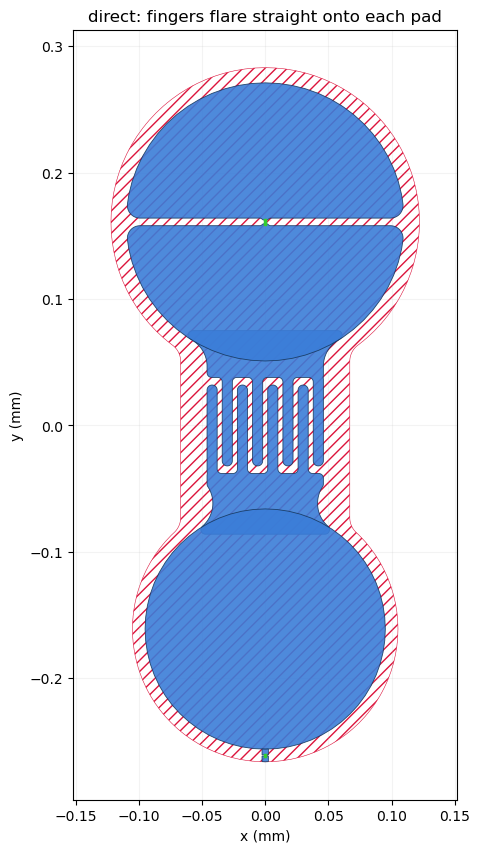

In [2]:
dd = coupled_pair(shape='direct')
sanity_checks(dd)
print('components:', list(dd.components.keys()))
show(dd, 'direct: fingers flare straight onto each pad')

3 metal nets = {grounded pad + comb a}, {floating island_R + comb b},
{floating island_L}. The coupler never touches `island_L`, so it does not
short the floating transmon across its junction. Ground is one connected
piece.

## 2. Dog-leg, Z

`shape='Z'` -- comb a dog-legs one way, comb b the other. The interdigital
fingers sit **off** the line between the two qubits.

metal nets (>300 um2): 3   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


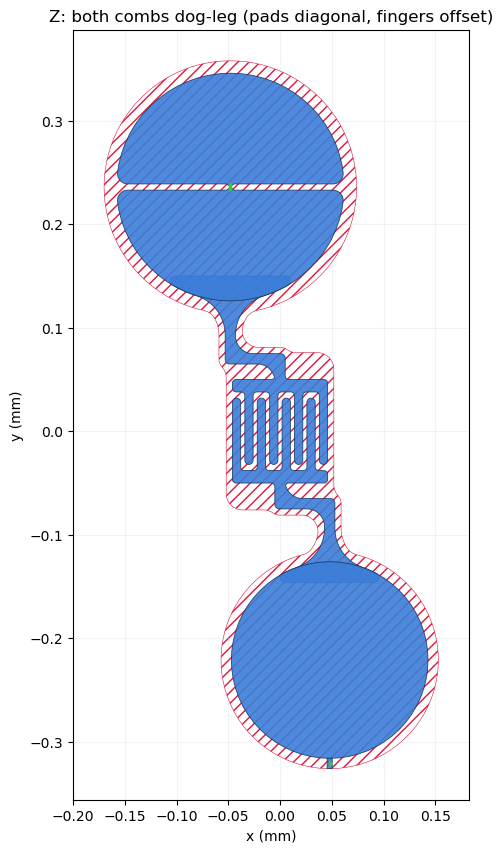

In [3]:
dz = coupled_pair(shape='Z')
sanity_checks(dz)
show(dz, 'Z: both combs dog-leg (pads diagonal, fingers offset)')

### zoom: the dog-leg bend + tangent flare

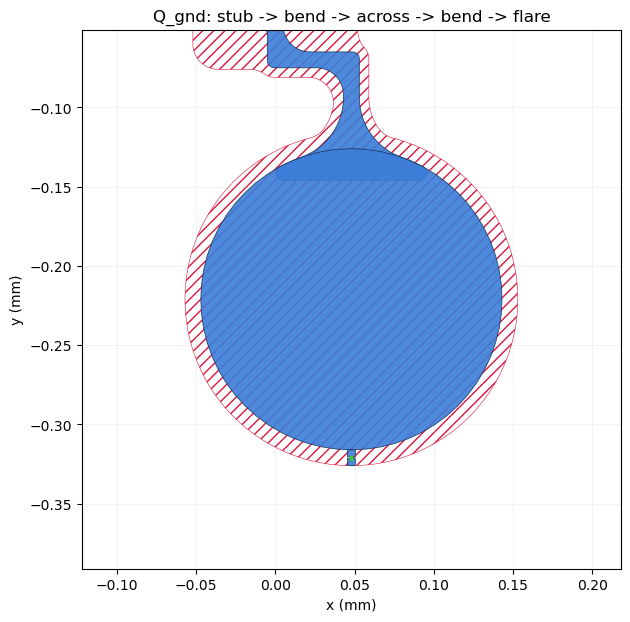

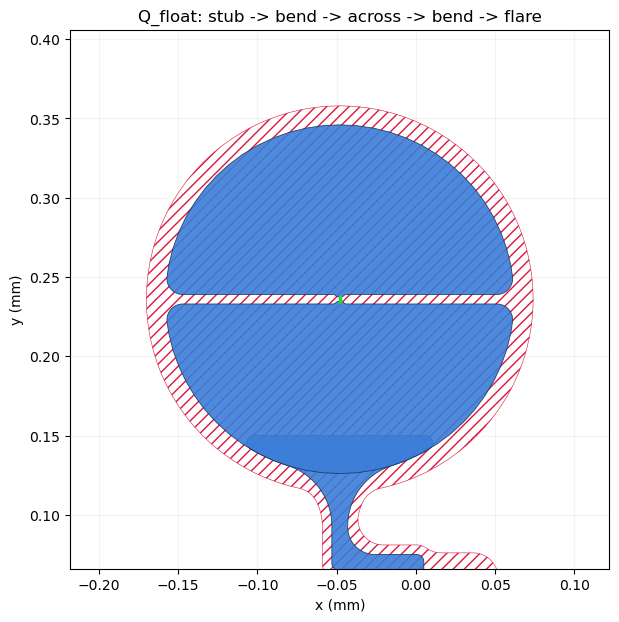

In [4]:
for nm in ('Q_gnd', 'Q_float'):
    q = dz.components[nm]
    cx = float(str(q.options['pos_x']).replace('um', '')) * 1e-3
    cy = float(str(q.options['pos_y']).replace('um', '')) * 1e-3
    show(dz, f'{nm}: stub -> bend -> across -> bend -> flare', figsize=(7, 7),
         xlim=(cx - 0.17, cx + 0.17), ylim=(cy - 0.17, cy + 0.17))

## 3. Dog-leg, U

`shape='U'` -- both combs dog-leg the same way, so both pads end up on one
side and the fingers on the other.

metal nets (>300 um2): 3   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


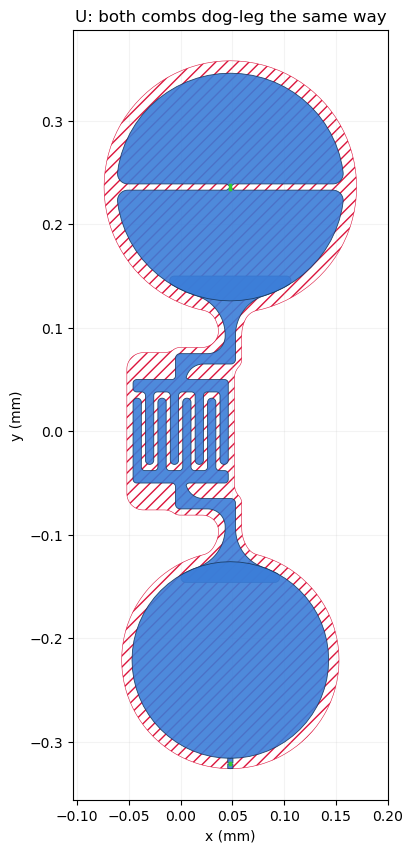

In [5]:
du = coupled_pair(shape='U')
sanity_checks(du)
show(du, 'U: both combs dog-leg the same way', figsize=(8, 10))

## 4. Orientation + leg lengths

`orientation_deg` rotates the whole coupler (the transmons follow);
`lead_out_um` / `lead_across_um` set how far each comb reaches out before
turning in.

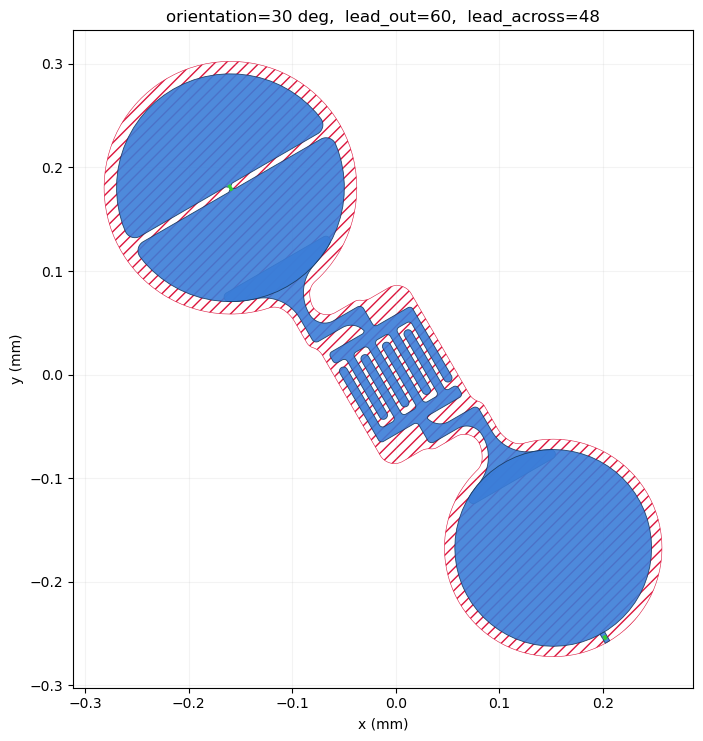

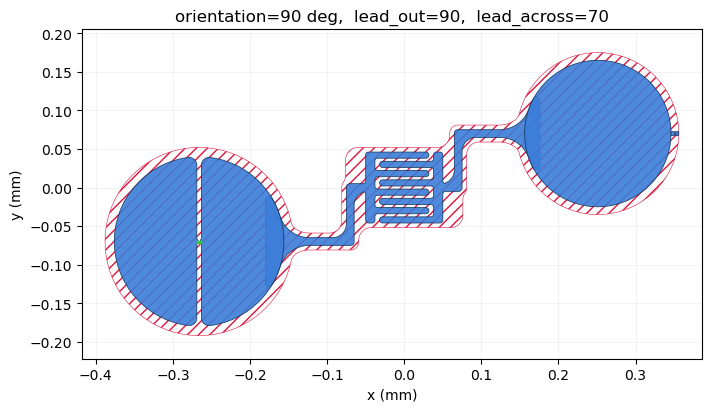

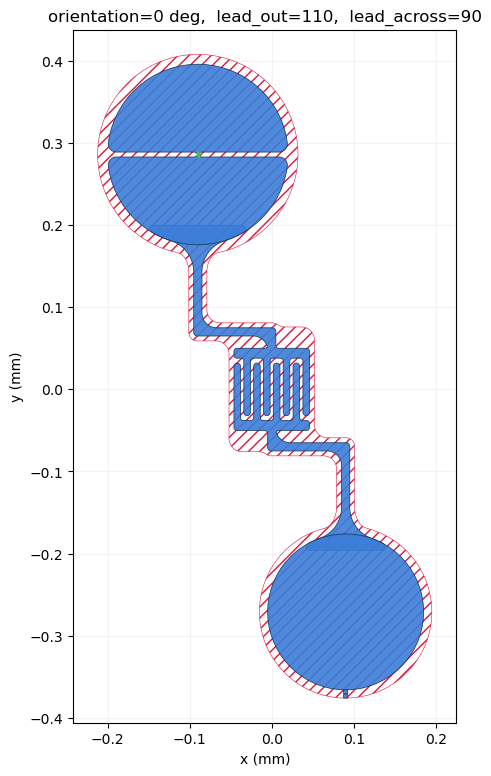

In [6]:
for ang, lo, la in [(30, 60, 48), (90, 90, 70), (0, 110, 90)]:
    d = coupled_pair(shape='Z', orientation_deg=ang, lead_out_um=lo, lead_across_um=la)
    show(d, f'orientation={ang} deg,  lead_out={lo},  lead_across={la}', figsize=(8, 9))

## 5. Two couplers on one pair of floating transmons

`both_couplers()` -- the payoff of the dog-leg: two `CircTransmonFloating`
coupled by **both** couplers at once. The `CapNInterdigitalRound` runs straight
between them (vertically) and merges onto each `island_L`; the
`SquidArrayCoupler` dog-legs around the east side and merges onto each
`island_R`. Each transmon's split is turned +-45 deg so the two couplers reach
different islands and never touch each other -- a fixed capacitance on one
island pair, a flux-tunable inductance on the other.

The SQUID coupler's placement is *solved* (`_solve_placement`) so its two
island centres land on the two transmons the cap coupler already positioned;
`lead_across` is auto-tuned so the SQUID's island spacing matches.

The two couplers + two transmons enclose a loop, so `sanity_checks` reports
**2 ground pieces** (inner + outer plate) -- tie them together in the solver,
as in `floating_ring/` section 5.

metal nets (>300 um2): 8   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]
components: ['cap', 'Q1', 'Q2', 'squid']
junction rows: 12  (10 SQUID + 2 transmon)
  Q1: cap->L 2185 um^2   squid->R 2153 um^2
  Q2: cap->L 2185 um^2   squid->R 2153 um^2
  cap touches squid? False


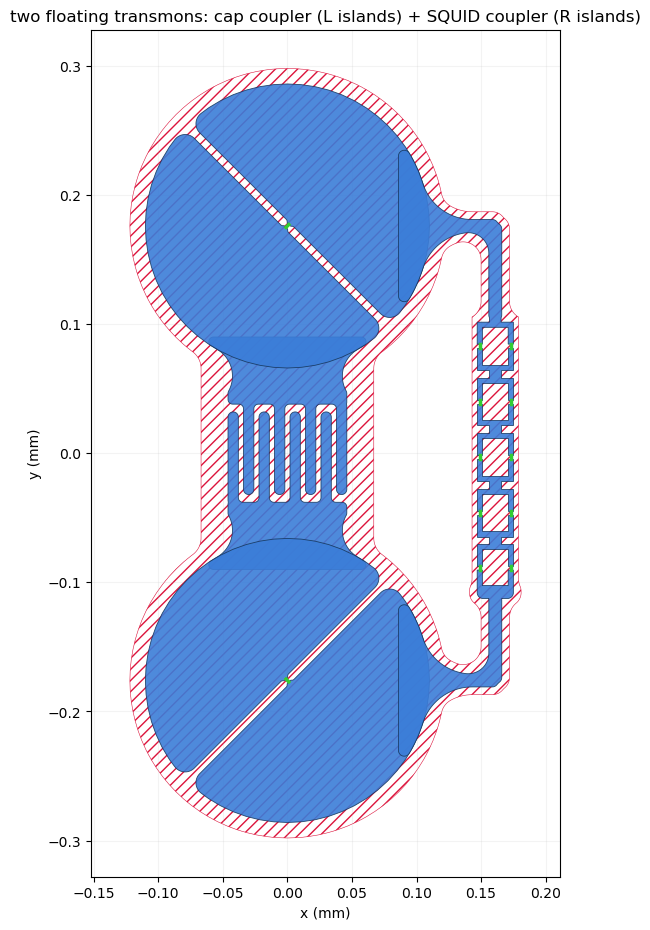

In [7]:
from build_design import both_couplers

db = both_couplers()
sanity_checks(db)
print('components:', list(db.components.keys()))
print('junction rows:', len(db.qgeometry.tables['junction']), ' (10 SQUID + 2 transmon)')

# which island each coupler merges onto
from shapely.ops import unary_union
t = db.qgeometry.tables['poly']; sub = t['subtract'].astype(bool)


def _cm(name):
    c = db.components[name].id
    return unary_union(list(t[(~sub) & (t.component == c)]['geometry']))


cap, sq = _cm('cap'), _cm('squid')
for q in ('Q1', 'Q2'):
    c = db.components[q].id
    L = unary_union(list(t[(~sub) & (t.component == c) & (t.name == 'island_L')]['geometry']))
    R = unary_union(list(t[(~sub) & (t.component == c) & (t.name == 'island_R')]['geometry']))
    print(f'  {q}: cap->L {cap.intersection(L).area * 1e6:.0f} um^2   '
          f'squid->R {sq.intersection(R).area * 1e6:.0f} um^2')
print('  cap touches squid?', cap.intersects(sq))

show(db, 'two floating transmons: cap coupler (L islands) + SQUID coupler (R islands)',
     figsize=(10, 11))

### 5b. Two grounded transmons, C || L in parallel on one pad

`both_couplers(grounded=True, ...)` -- two `CircTransmon` (single circular pad
each) instead of the split floating qubits. Now **both** couplers merge onto
the *same* pad of each transmon, from different sides (cap from N/S, SQUID from
E), so the fixed capacitance and the tunable SQUID inductance sit truly in
parallel between the two pad nodes. Each JJ is put at 180 deg (west), clear of
both couplers.

`extra_gap_um` widens the transmon gap and `cap_lead_width_um` keeps the cap
lead a clean CPW-style trace; the SQUID's `lead_across` is auto-tuned to the
gap. `2 * n_squids + 2` junction rows.

metal nets (>300 um2): 13   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]
transmon separation: 552 um    junction rows: 26  (24 SQUID + 2 transmon)
  Q1: cap->pad 2185 um^2   squid->pad 2153 um^2
  Q2: cap->pad 2185 um^2   squid->pad 2153 um^2
  cap touches squid? False


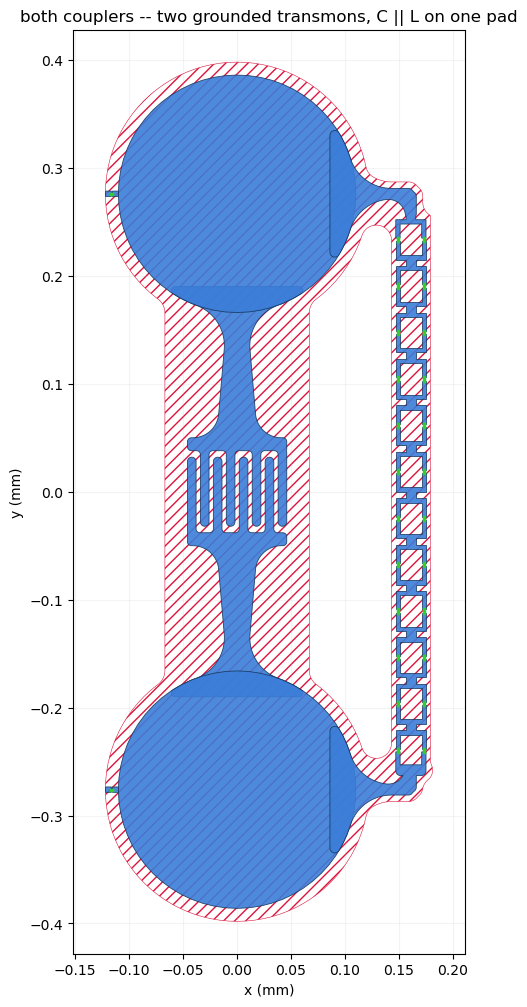

In [8]:
dw = both_couplers(grounded=True, extra_gap_um=100, n_squids=12, cap_lead_width_um=18)
sanity_checks(dw)
q1y = float(str(dw.components['Q1'].options['pos_y'])[:-2])
q2y = float(str(dw.components['Q2'].options['pos_y'])[:-2])
print(f'transmon separation: {abs(q2y - q1y):.0f} um    '
      f'junction rows: {len(dw.qgeometry.tables["junction"])}  (24 SQUID + 2 transmon)')

# both couplers merge onto the same single pad of each grounded transmon
from shapely.ops import unary_union
t = dw.qgeometry.tables['poly']; sub = t['subtract'].astype(bool)


def _cm(name):
    c = dw.components[name].id
    return unary_union(list(t[(~sub) & (t.component == c)]['geometry']))


cap, sq = _cm('cap'), _cm('squid')
for q in ('Q1', 'Q2'):
    pad = _cm(q)
    print(f'  {q}: cap->pad {cap.intersection(pad).area * 1e6:.0f} um^2   '
          f'squid->pad {sq.intersection(pad).area * 1e6:.0f} um^2')
print('  cap touches squid?', cap.intersects(sq))

show(dw, 'both couplers -- two grounded transmons, C || L on one pad', figsize=(8, 12))

## Interactive (MetalGUI)

Opens a **separate Qt window** (not inline). The `metal` logger is quieted
first. Skip if no display.

In [9]:
import os, logging
logging.getLogger('metal').setLevel(logging.ERROR)

_disp = os.environ.get('DISPLAY', '') or os.environ.get('WAYLAND_DISPLAY', '')
if _disp and os.environ.get('QT_QPA_PLATFORM') == 'offscreen':
    del os.environ['QT_QPA_PLATFORM']

if not _disp:
    print('[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots '
          'above already show the geometry.')
else:
    get_ipython().run_line_magic('gui', 'qt')
    from qiskit_metal import MetalGUI
    design = coupled_pair(shape='Z')
    gui = MetalGUI(design)
    gui.rebuild()
    gui.autoscale()

[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots above already show the geometry.
